# Three more search algorithms: Iterative Deepening, Bidirectional Search and Uniform Cost Search

In the last notebooks we met DFS and BFS. Each one has a weakness.

* DFS uses little memory but can return a long, roundabout path.
* BFS finds the path with the fewest steps but can use a lot of memory.
* Both of them ignore how much each step costs.

The three algorithms in this notebook fix one of those problems each.

| Algorithm | The idea | What it fixes |
|---|---|---|
| Iterative Deepening Search (IDS) | Run DFS with a depth limit of 0, then 1, then 2, and so on | Gets the shortest path like BFS while using the small memory of DFS |
| Bidirectional Search | Search from the start and from the goal at the same time until the two searches meet | Visits far fewer nodes than a one-sided BFS |
| Uniform Cost Search (UCS) | Always expand the node with the cheapest total cost so far | Finds the cheapest path when edges have different costs |

Every algorithm has two examples. One is on a **tree** and one is on a **graph**. As before, one example uses a data structure that comes ready-made in Python, and the other uses a plain list, so you can see that the idea does not depend on the container. You will build each tree and graph in code, draw it, run the search, and watch it animated.

---
## New Python ideas used in this notebook

A few small things appear here that we have not used before. Read this section first. Each one is only a few lines.

We already know the stack (`list` with `append` and `pop`, or `queue.LifoQueue`) and the queue (`list` with `pop(0)`, or `collections.deque`). We will keep using them.

### 1. Tuples, and unpacking them

A tuple is a fixed group of values written in round brackets. We use tuples to store a neighbor together with the cost of reaching it.

In [ ]:
road = ("B", 2)             # a tuple: the neighbor is B, the cost is 2
print(road[0], road[1])

neighbor, cost = road       # unpacking: the two values go into two variables
print(neighbor, cost)

roads_from_A = [("B", 2), ("C", 8)]          # a list of tuples
for neighbor, cost in roads_from_A:          # unpacking right in the for loop
    print("from A we can reach", neighbor, "for a cost of", cost)

B 2 4
B 2 4
from A we can reach B for a cost of 2
from A we can reach C for a cost of 8


A function can also return two values at once. They come back as a tuple, and we unpack them in the same way.

In [2]:
def smallest_and_largest(numbers):
    return min(numbers), max(numbers)

low, high = smallest_and_largest([4, 9, 1, 7])
print(low, high)

1 9


### 2. A weighted graph in a dictionary

So far each node mapped to a list of neighbors. When the roads have costs, each node maps to a list of `(neighbor, cost)` tuples instead.

In [3]:
weighted = {
    "A": [("B", 2), ("C", 8)],
    "B": [("A", 2)],
    "C": [("A", 8)],
}
print(weighted["A"])

[('B', 2), ('C', 8)]


### 3. Comparing tuples, and `min()` on a list of tuples

Python compares tuples by their first value, and only looks at the second one when the first values are equal. That means `min()` on a list of `(cost, name)` tuples returns the cheapest one.

In [4]:
print((2, "B") < (5, "A"))        # True: 2 is smaller than 5, so the names are never compared
print((3, "A") < (3, "B"))        # True: same cost, so "A" is smaller than "B"

waiting = [(8, "C"), (2, "B"), (5, "D")]
cheapest = min(waiting)           # (2, 'B')
waiting.remove(cheapest)          # remove that exact item from the list
print(cheapest, waiting)

True
True
(2, 'B') [(8, 'C'), (5, 'D')]


### 4. A priority queue with `heapq`

A stack gives back the newest item and a queue gives back the oldest item. A **priority queue** gives back the **smallest** item, whatever order the items went in. Python has one built in, in the `heapq` module.

* `heapq.heappush(heap, item)` adds an item.
* `heapq.heappop(heap)` removes and returns the smallest item.

The `heap` itself is just a normal list that you start empty. Do not print it to look at the order. Only the smallest item is guaranteed to be easy to get, and the rest of the list is arranged in a way that only `heappop` understands.

In [57]:
import heapq

chores = []
heapq.heappush(chores, (5, "wash the car"))
heapq.heappush(chores, (1, "cook dinner"))
heapq.heappush(chores, (3, "study"))                 

while len(chores) > 0:
    print(heapq.heappop(chores))      # always the smallest number first

(1, 'cook dinner')
(3, 'study')
(5, 'wash the car')


### 5. Reversing a list with `[::-1]`, and joining lists with `+`

`[::-1]` gives a reversed copy of a list. We need it to turn a path that was built backwards from the goal into a path that reads forwards.

In [ ]:
print([1, 2, 3][::-1])                    # [3, 2, 1]

from_start = ["S", "M"]                   # the path from the start to M
from_goal = ["T", "N"]                    # the path from the goal to N, built backwards
print(from_start + from_goal[::-1])       # ['S', 'M', 'N', 'T']

[3]
['S', 'M', 'N', 'T']


### 6. A dictionary that stores a path for every node

Until now we kept one `visited` list. In bidirectional search we want to remember **how we reached each node**, so we use a dictionary from a node to the path that reached it. Checking `"B" in paths` tells us if B was reached, and `paths["B"]` gives the path.

In [ ]:
paths = {"A": ["A"]}                      # A was reached by the path [A]
paths["B"] = paths["A"] + ["B"]           # B was reached through A
paths["D"] = paths["B"] + ["D"]

print("D" in paths, "Z" in paths)
print(paths["D"])

{'A': ['A'], 'B': ['A', 'B'], 'D': ['A', 'B', 'D']}
True False
['A', 'B', 'D']


### 7. Doing something an exact number of times

`for _ in range(n)` repeats the body `n` times. The underscore is a normal variable name that people use when they do not need the counter. The number `n` is worked out once, before the loop starts. Bidirectional search uses this to process exactly one level of a queue, even though the queue keeps growing while we work.

In [8]:
queue = ["a", "b", "c"]
for _ in range(len(queue)):        # len(queue) is 3, and it stays 3 for this loop
    item = queue.pop(0)
    queue.append(item + "!")       # the queue grows, but we still only go around 3 times
print(queue)

['a!', 'b!', 'c!']


---
## Setup

The next cell has the drawing and animation code. It only draws things on the screen, so run it and skip reading it. The search algorithms are written in the sections below.

In the algorithm code, a line ending with `# animation only` just saves a snapshot for the animation. It does not affect the search, so ignore those lines when you read the logic.

In [80]:
# Drawing and animation helpers. They only draw things on the screen and are not part of the algorithms.
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle, Rectangle, Patch
from IPython.display import HTML, display
from collections import deque

COLOR = {"current": "#f5a623", "visited": "#8fd19e", "frontier": "#ffe066", "unseen": "#e6e6e6",
         "path": "#ee6c4d", "stale": "#cfcfcf", "back_done": "#9ecae1", "back_wait": "#d4b9f0"}


def tree_edges(tree):
    """Edges of a tree stored as {parent: [children]} or {parent: [(child, weight), ...]}."""
    edges, weights = [], {}
    for parent in tree:
        for item in tree[parent]:
            child, w = (item if isinstance(item, tuple) else (item, None))
            edges.append((parent, child))
            if w is not None:
                weights[(parent, child)] = w
    return edges, weights


def graph_edges(graph):
    """Edges of an undirected graph. Each edge is returned once."""
    seen, edges, weights = set(), [], {}
    for a in graph:
        for item in graph[a]:
            b, w = (item if isinstance(item, tuple) else (item, None))
            key = frozenset((a, b))
            if key not in seen:
                seen.add(key)
                edges.append((a, b))
                if w is not None:
                    weights[(a, b)] = w
    return edges, weights


def draw_structure(ax, pos, edges, colors=None, path_edges=(), weights=None, notes=None):
    for a, b in edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color="#9a9a9a", linewidth=2, zorder=1)
    for a, b in path_edges:
        (x1, y1), (x2, y2) = pos[a], pos[b]
        ax.plot([x1, x2], [y1, y2], color=COLOR["path"], linewidth=5, zorder=2)
    if weights:
        for (a, b), w in weights.items():
            (x1, y1), (x2, y2) = pos[a], pos[b]
            ax.text((x1 + x2) / 2, (y1 + y2) / 2, str(w), ha="center", va="center", fontsize=11, zorder=5,
                    bbox=dict(boxstyle="round,pad=0.15", facecolor="white", edgecolor="#bbbbbb"))
    for name, (x, y) in pos.items():
        color = colors[name] if colors else COLOR["unseen"]
        ax.add_patch(Circle((x, y), 0.3, facecolor=color, edgecolor="#333333", linewidth=1.5, zorder=3))
        ax.text(x, y, name, ha="center", va="center", fontsize=13, zorder=4)
        if notes and name in notes:
            ax.text(x, y - 0.55, notes[name], ha="center", va="center", fontsize=10, color="#1b4f9c", zorder=6,
                    bbox=dict(boxstyle="round,pad=0.1", facecolor="white", edgecolor="none", alpha=0.9))


def show_structure(pos, edges, title, weights=None):
    fig, ax = plt.subplots(figsize=(10, 5))
    draw_structure(ax, pos, edges, weights=weights)
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 1, max(xs) + 1)
    ax.set_ylim(min(ys) - 1, max(ys) + 1)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.show()


def record(trace, **info):
    """Saves one snapshot for the animation. Does nothing when trace is None."""
    if trace is not None:
        trace.append({k: (list(v) if isinstance(v, (list, deque)) else dict(v) if isinstance(v, dict) else v)
                      for k, v in info.items()})


def base_colors(nodes, current, done, waiting):
    colors = {}
    for n in nodes:
        if n in current:
            colors[n] = COLOR["current"]
        elif n in done:
            colors[n] = COLOR["visited"]
        elif n in waiting:
            colors[n] = COLOR["frontier"]
        else:
            colors[n] = COLOR["unseen"]
    return colors


# ---- turn the recorded snapshots into frames for each algorithm
def frames_ids(trace, nodes):
    frames = []
    for i, s in enumerate(trace):
        frames.append({
            "title": f"Iterative deepening, limit = {s['limit']}  (frame {i + 1} of {len(trace)})\n"
                     f"visiting {s['current']}, visited in this round: {s['visited']}",
            "colors": base_colors(nodes, [s["current"]], s["visited"], s["frontier"]),
            "rows": [("Stack (top is the rightmost box)", [(n, "normal") for n in s["frontier"]], COLOR["frontier"])],
            "notes": {}})
    return frames


def frames_ucs(trace, nodes):
    frames = []
    for i, s in enumerate(trace):
        tentative = {}
        for cost, n in s["frontier"]:
            if n not in s["visited"]:
                tentative[n] = min(cost, tentative.get(n, cost))
        notes = {n: str(c) for n, c in s["visited"].items()}
        notes.update({n: f"({c})" for n, c in tentative.items()})
        items = [(f"{n}({c})", "stale" if n in s["visited"] else "normal") for c, n in sorted(s["frontier"])]
        frames.append({
            "title": f"Uniform cost search, step {i + 1} of {len(trace)}: visiting {s['current']} "
                     f"at total cost {s['cost']}",
            "colors": base_colors(nodes, [s["current"]], list(s["visited"]), list(tentative)),
            "rows": [("Priority queue (cheapest on the left)", items, COLOR["frontier"])],
            "notes": notes})
    return frames


def frames_bidirectional(trace, nodes):
    frames = []
    for i, s in enumerate(trace):
        colors = {}
        for n in nodes:
            if n in s["current"]:
                colors[n] = COLOR["current"]
            elif n in s["forward_done"]:
                colors[n] = COLOR["visited"]
            elif n in s["backward_done"]:
                colors[n] = COLOR["back_done"]
            elif n in s["forward_queue"]:
                colors[n] = COLOR["frontier"]
            elif n in s["backward_queue"]:
                colors[n] = COLOR["back_wait"]
            else:
                colors[n] = COLOR["unseen"]
        title = (f"Bidirectional BFS, round {i + 1} of {len(trace)}: the {s['side']} search "
                 f"expands {', '.join(s['current'])}")
        if s["found"]:
            title += "\nThe two searches meet. Path: " + " -> ".join(s["found"])
        frames.append({
            "title": title, "colors": colors, "notes": {},
            "rows": [("Forward queue (front on the left)", [(n, "normal") for n in s["forward_queue"]], COLOR["frontier"]),
                     ("Backward queue (front on the left)", [(n, "normal") for n in s["backward_queue"]], COLOR["back_wait"])]})
    return frames


LEGEND_IDS = [Patch(color=COLOR["current"], label="node being visited"),
              Patch(color=COLOR["visited"], label="visited in this round"),
              Patch(color=COLOR["frontier"], label="waiting in the stack"),
              Patch(color=COLOR["unseen"], label="not discovered yet"),
              Patch(color=COLOR["path"], label="final path")]

LEGEND_UCS = [Patch(color=COLOR["current"], label="node being visited"),
              Patch(color=COLOR["visited"], label="visited (cost is final)"),
              Patch(color=COLOR["frontier"], label="waiting, (cost) is the best so far"),
              Patch(color=COLOR["unseen"], label="not discovered yet"),
              Patch(color=COLOR["path"], label="cheapest path")]

LEGEND_BIDI = [Patch(color=COLOR["current"], label="expanded in this round"),
               Patch(color=COLOR["visited"], label="forward: done"),
               Patch(color=COLOR["frontier"], label="forward: waiting"),
               Patch(color=COLOR["back_done"], label="backward: done"),
               Patch(color=COLOR["back_wait"], label="backward: waiting"),
               Patch(color=COLOR["path"], label="final path")]


def play(pos, edges, frames, path, legend, weights=None, interval=1400):
    xs = [p[0] for p in pos.values()]
    ys = [p[1] for p in pos.values()]
    longest = max([len(row[1]) for f in frames for row in f["rows"]] + [1])
    x_min, y_min = min(xs), min(ys)
    x_max = max(max(xs) + 1.2, x_min + 1.0 * longest + 0.6)
    n_rows = len(frames[0]["rows"])
    box_top = y_min - 1.3
    fig, ax = plt.subplots(figsize=(9, 7))

    def update(i):
        ax.clear()
        f = frames[i]
        is_last = i == len(frames) - 1
        colors = dict(f["colors"])
        path_edges = []
        if is_last and path:
            for n in path:
                colors[n] = COLOR["path"]
            path_edges = list(zip(path, path[1:]))
        draw_structure(ax, pos, edges, colors, path_edges, weights, f["notes"])
        for r, (label, items, color) in enumerate(f["rows"]):
            y = box_top - 0.7 - r * 1.7
            ax.text(x_min - 0.4, y + 0.95, label, fontsize=9, ha="left")
            if not items:
                ax.text(x_min - 0.4, y + 0.3, "(empty)", fontsize=10, ha="left")
            for k, (text, style) in enumerate(items):
                ax.add_patch(Rectangle((x_min - 0.4 + 1.0 * k, y), 0.9, 0.7,
                                       facecolor=COLOR["stale"] if style == "stale" else color, edgecolor="#333333"))
                ax.text(x_min + 0.05 + 1.0 * k, y + 0.35, text, ha="center", va="center", fontsize=10)
        ax.set_xlim(x_min - 1, x_max)
        ax.set_ylim(box_top - 0.7 - (n_rows - 1) * 1.7 - 0.4, max(ys) + 2.0)
        ax.set_aspect("equal")
        ax.axis("off")
        ax.set_title(f["title"], fontsize=11)
        ax.legend(handles=legend, loc="upper center", ncol=3, fontsize=8, frameon=False)

    anim = FuncAnimation(fig, update, frames=len(frames), interval=interval, repeat=False)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def bfs_visit_count(graph, start, goal):
    """Plain BFS, used only to compare how many nodes it visits."""
    queue, seen, count = deque([start]), {start}, 0
    while queue:
        node = queue.popleft()
        count += 1
        if node == goal:
            return count
        for nb in graph[node]:
            if nb not in seen:
                seen.add(nb)
                queue.append(nb)
    return count

---
# Part 1: Iterative Deepening Search (IDS)

### The idea

DFS can dive down a very long branch, and BFS needs a lot of memory. IDS gets the best of both:

1. Run a DFS that is **not allowed to go deeper than 0** steps from the start. If the goal is not found, throw everything away.
2. Run it again with a limit of **1**.
3. Then **2**, then **3**, and keep going until the goal is found.

A DFS with a depth limit is called a **depth-limited search**. IDS is just a loop that calls it with a larger limit each time.

Each round only goes as deep as it needs to, so the first round that finds the goal has used the smallest possible depth. That is the shortest path, the same answer BFS gives. And since each round is a DFS, the memory use stays small.

You might worry about repeating work. The nodes near the top get visited again in every round, but there are very few of them. Most of the nodes in a search sit at the bottom levels, so the repeated work is a small part of the total.

## Example 1: IDS on a tree (using the built-in stack `queue.LifoQueue`)

### Build the tree

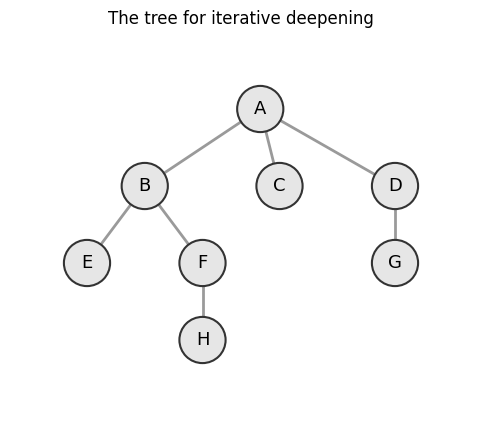

In [86]:
tree = {
    "A": ["B", "C", "D"],
    "B": ["E", "F"],
    "C": [],
    "D": ["G"],
    "E": [],
    "F": ["H"],
    "G": [],
    "H": [],
}

# where each node is drawn: (x, y)
tree_pos = {
    "A": (2.25, 3),
    "B": (0.75, 2), "C": (2.5, 2), "D": (4.0, 2),
    "E": (0.0, 1),  "F": (1.5, 1), "G": (4.0, 1),
    "H": (1.5, 0),
}

# tree = {
#     "A": ["B", "C", "D"],
#     "B": ["E", "F", "G"],
#     "C": ["H", "I", "J"],
#     "D": ["K", "L", "M"],
#     "E": ["N", "O"],
#     "F": ["P", "Q"],
#     "G": ["R", "S"],
#     "H": ["T", "U"],
#     "I": ["V", "W"],
#     "J": ["X", "Y"],
#     "K": ["Z", "AA"],
#     "L": ["AB", "AC"],
#     "M": ["AD", "AE"],
#     **{node: [] for node in [
#         "N", "O", "P", "Q", "R", "S", "T", "U",
#         "V", "W", "X", "Y", "Z", "AA", "AB", "AC",
#         "AD", "AE"
#     ]}
# }

# tree_pos = {
#     "A": (6, 4),

#     "B": (2, 3), "C": (6, 3), "D": (10, 3),

#     "E": (0.5, 2), "F": (2, 2), "G": (3.5, 2),
#     "H": (4.5, 2), "I": (6, 2), "J": (7.5, 2),
#     "K": (8.5, 2), "L": (10, 2), "M": (11.5, 2),

#     "N": (0, 1), "O": (1, 1),
#     "P": (1.5, 1), "Q": (2.5, 1),
#     "R": (3, 1), "S": (4, 1),
#     "T": (4, 1), "U": (5, 1),
#     "V": (5.5, 1), "W": (6.5, 1),
#     "X": (7, 1), "Y": (8, 1),
#     "Z": (8, 1), "AA": (9, 1),
#     "AB": (9.5, 1), "AC": (10.5, 1),
#     "AD": (11, 1), "AE": (12, 1),
# }



ROOT, TREE_GOAL = "A", "H"
t_edges, _ = tree_edges(tree)
show_structure(tree_pos, t_edges, "The tree for iterative deepening")

### The algorithm

This is the DFS from the earlier notebook with one extra rule: a node is only expanded if the path to it is shorter than `limit`. The number of steps in a path is `len(path) - 1`.

* `depth_limited_tree` is one round, for one value of `limit`.
* `ids_tree` is the loop that tries `limit = 0, 1, 2, ...` and stops at the first round that finds the goal.

A tree has no cycles, so we do not need to check for repeated nodes.

In [87]:
from queue import LifoQueue

def depth_limited_tree(tree, root, goal, limit, trace=None):
    stack = LifoQueue()
    stack.put([root])
    visited = []                                   # nodes visited in this round only

    while not stack.empty():
        path = stack.get()                         # newest path first, as in DFS
        node = path[-1]
        visited.append(node)

        if node == goal:
            record(trace, current=node, frontier=[p[-1] for p in stack.queue], visited=visited, limit=limit)  # animation only
            return path

        if len(path) - 1 < limit:                  # only go deeper if we are above the limit
            for child in reversed(tree[node]):
                stack.put(path + [child])

        record(trace, current=node, frontier=[p[-1] for p in stack.queue], visited=visited, limit=limit)      # animation only

    return None                                    # this round did not find the goal


def ids_tree(tree, root, goal, max_depth=10, trace=None):
    for limit in range(max_depth + 1):             # limit = 0, 1, 2, ...
        path = depth_limited_tree(tree, root, goal, limit, trace)
        if path is not None:
            return path, limit
    return None, None

### Run it

In [88]:
ids_tree_trace = []
ids_tree_path, ids_tree_limit = ids_tree(tree, ROOT, TREE_GOAL, trace=ids_tree_trace)

print("Path:", ids_tree_path)
print("The goal was found when the depth limit reached", ids_tree_limit)
print()
for limit in range(ids_tree_limit + 1):
    count = sum(1 for s in ids_tree_trace if s["limit"] == limit)
    print("limit", limit, "-> visited", count, "nodes")

Path: ['A', 'B', 'F', 'H']
The goal was found when the depth limit reached 3

limit 0 -> visited 1 nodes
limit 1 -> visited 4 nodes
limit 2 -> visited 7 nodes
limit 3 -> visited 5 nodes


Each round visits a few more nodes than the one before. In total IDS made 17 visits here, while a single plain DFS would have reached `H` after 5 visits, so on a tiny tree like this one the repeated work is easy to see.

The picture changes on bigger trees. When every node has many children, the bottom level is much larger than all the levels above it put together, so the early rounds are only a small fraction of the total work.

### Watch IDS on the tree

The title shows the current depth limit. Each time the limit goes up by one, the search starts again from the root. Notice that a node at the depth limit is visited but its children are not added to the stack.

In [89]:
play(tree_pos, t_edges, frames_ids(ids_tree_trace, list(tree_pos)), ids_tree_path, LEGEND_IDS)

---
## Example 2: IDS on a graph (using a plain list as the stack)

A graph can contain cycles. In this graph the loop `A - B - E - F - C - A` would let a search walk in circles. In the earlier DFS we kept a `visited` list for the whole search. A depth-limited search needs something different.

The reason is that a node can be reached by a long path first and by a short path later. If a global `visited` list blocked the second visit, the search could miss the goal when the limit is tight. So instead, each path only checks that it does not revisit **a node that is already on that same path**. That is enough to stop circles, and the search stays correct.

### Build the graph

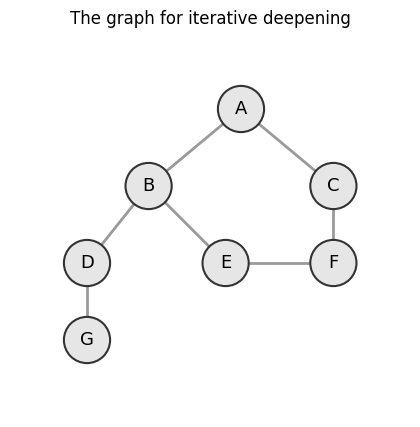

In [92]:
graph = {
    "A": ["B", "C"],
    "B": ["A", "D", "E"],
    "C": ["A", "F"],
    "D": ["B", "G"],
    "E": ["B", "F"],
    "F": ["C", "E"],
    "G": ["D"],
}

graph_pos = {
    "A": (2.0, 3),
    "B": (0.8, 2), "C": (3.2, 2),
    "D": (0.0, 1), "E": (1.8, 1), "F": (3.2, 1),
    "G": (0.0, 0),
}

START, GRAPH_GOAL = "A", "G"
g_edges, _ = graph_edges(graph)
show_structure(graph_pos, g_edges, "The graph for iterative deepening")

### The algorithm

The stack is a plain list: `append` pushes and `pop()` takes the newest item. The only difference from the tree version is the check `if neighbor not in path`.

In [ ]:
def depth_limited_graph(graph, start, goal, limit, trace=None):
    stack = [[start]]                              # a list used as a stack
    visited = []                                   # nodes visited in this round only (may repeat)

    while len(stack) > 0:
        path = stack.pop()                         # newest path (last item)
        node = path[-1]
        visited.append(node)

        if node == goal:
            record(trace, current=node, frontier=[p[-1] for p in stack], visited=visited, limit=limit)  # animation only
            return path

        if len(path) - 1 < limit:                  # only go deeper if we are above the limit
            for neighbor in reversed(graph[node]):
                if neighbor not in path:           # do not walk in a circle along this path
                    stack.append(path + [neighbor])

        record(trace, current=node, frontier=[p[-1] for p in stack], visited=visited, limit=limit)      # animation only

    return None


def ids_graph(graph, start, goal, max_depth=10, trace=None):
    for limit in range(max_depth + 1):
        path = depth_limited_graph(graph, start, goal, limit, trace)
        if path is not None:
            return path, limit
    return None, None

### Run it

In [97]:
ids_graph_trace = []
ids_graph_path, ids_graph_limit = ids_graph(graph, START, GRAPH_GOAL, trace=ids_graph_trace)

print("Path:", ids_graph_path)
print("The goal was found when the depth limit reached", ids_graph_limit)
print()
for limit in range(ids_graph_limit + 1):
    count = sum(1 for s in ids_graph_trace if s["limit"] == limit)
    print("limit", limit, "-> visited", count, "nodes")

Path: ['A', 'B', 'D', 'G']
The goal was found when the depth limit reached 3

limit 0 -> visited 1 nodes
limit 1 -> visited 3 nodes
limit 2 -> visited 6 nodes
limit 3 -> visited 4 nodes


The plain DFS from the earlier notebook returned `A -> B -> E -> F` for this same graph, which is three steps. IDS returned `A -> C -> F`, which is two steps. The first round that is deep enough to reach `F` is the round that finds the shortest path.

### Watch IDS on the graph

In [98]:
play(graph_pos, g_edges, frames_ids(ids_graph_trace, list(graph_pos)), ids_graph_path, LEGEND_IDS)

---
# Part 2: Bidirectional Search

### The idea

Imagine two people looking for each other in a big building. It is faster if **both** of them start walking, one from each end, and they stop when they meet, than if one of them has to find the other alone.

Bidirectional search does exactly this. One BFS starts at the **start** and spreads outward. A second BFS starts at the **goal** and spreads outward as well. As soon as the two searches touch, we join the two halves into one path.

Why is this faster? A BFS that looks `d` steps away has to visit a huge number of nodes, because the number of nodes grows quickly with every step. Two searches that each only look `d/2` steps away visit far fewer nodes in total.

Two details in our code:

* We expand **one whole level** of one side at a time. When the two searches touch during a level, we collect every meeting from that level and return the shortest joined path. This keeps the answer a shortest path.
* We always expand the side that has **fewer nodes waiting**. A side with a small queue is cheap to expand, and this keeps the two searches balanced.

Bidirectional search needs to be able to move along an edge backwards, so it works on graphs where an edge can be walked in both directions.

### How the code stores the two searches

* `forward_paths[node]` is the path from the **start** to `node`.
* `backward_paths[node]` is the path from the **goal** to `node`.

When one search finds a neighbor that the other search has already reached, the two paths are joined. The backward path is reversed with `[::-1]` so that the final path reads from start to goal.

## Example 1: Bidirectional search on a tree (using the built-in queue `collections.deque`)

### Build the tree

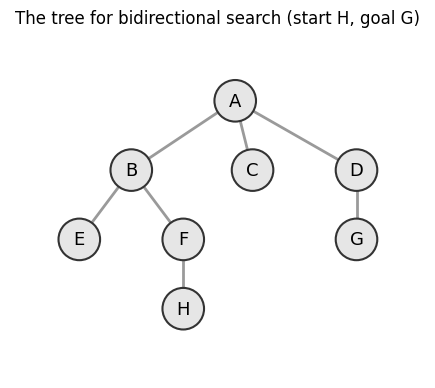

In [18]:
# A tree is a graph with no cycles. For a bidirectional search we need to walk edges in both
# directions, so every node lists its parent as well as its children.
bi_tree = {
    "A": ["B", "C", "D"],
    "B": ["A", "E", "F"],
    "C": ["A"],
    "D": ["A", "G"],
    "E": ["B"],
    "F": ["B", "H"],
    "G": ["D"],
    "H": ["F"],
}

bi_tree_pos = {
    "A": (2.25, 3),
    "B": (0.75, 2), "C": (2.5, 2), "D": (4.0, 2),
    "E": (0.0, 1),  "F": (1.5, 1), "G": (4.0, 1),
    "H": (1.5, 0),
}

BI_TREE_START, BI_TREE_GOAL = "H", "G"
bt_edges, _ = graph_edges(bi_tree)
show_structure(bi_tree_pos, bt_edges, "The tree for bidirectional search (start H, goal G)")

### The algorithm

`expand_level` takes one search (its queue and its dictionary of paths) and expands exactly one level of it. It returns the meetings it found and the nodes it expanded. `bidirectional_tree` calls it again and again, choosing the side with the smaller queue each time, until a meeting is found.

The queues are `collections.deque` objects. `popleft()` removes the oldest node.

In [19]:
from collections import deque

def expand_level(graph, queue, my_paths, other_paths, i_am_forward):
    meetings = []                                  # full paths found when the two searches touch
    expanded = []

    for _ in range(len(queue)):                    # exactly one level of this queue
        node = queue.popleft()
        expanded.append(node)

        for neighbor in graph[node]:
            if neighbor in other_paths:            # the other search already reached this node
                if i_am_forward:
                    meetings.append(my_paths[node] + other_paths[neighbor][::-1])
                else:
                    meetings.append(other_paths[neighbor] + my_paths[node][::-1])
            elif neighbor not in my_paths:         # a new node for this search
                my_paths[neighbor] = my_paths[node] + [neighbor]
                queue.append(neighbor)

    return meetings, expanded


def bidirectional_tree(graph, start, goal, trace=None):
    if start == goal:
        return [start]

    forward_paths = {start: [start]}               # paths that begin at the start
    backward_paths = {goal: [goal]}                # paths that begin at the goal
    forward_queue = deque([start])
    backward_queue = deque([goal])
    forward_done, backward_done = [], []           # nodes each side has expanded

    while len(forward_queue) > 0 and len(backward_queue) > 0:
        if len(forward_queue) <= len(backward_queue):          # expand the smaller side
            side = "forward"
            meetings, expanded = expand_level(graph, forward_queue, forward_paths, backward_paths, True)
            forward_done += expanded
        else:
            side = "backward"
            meetings, expanded = expand_level(graph, backward_queue, backward_paths, forward_paths, False)
            backward_done += expanded

        found = min(meetings, key=len) if meetings else None   # the shortest meeting
        record(trace, side=side, current=expanded, forward_done=forward_done, backward_done=backward_done,
               forward_queue=forward_queue, backward_queue=backward_queue, found=found)   # animation only

        if found is not None:
            return found

    return None

### Run it

In [20]:
bi_tree_trace = []
bi_tree_path = bidirectional_tree(bi_tree, BI_TREE_START, BI_TREE_GOAL, bi_tree_trace)

last = bi_tree_trace[-1]
print("Path:", bi_tree_path)
print("Nodes expanded by the forward search: ", last["forward_done"])
print("Nodes expanded by the backward search:", last["backward_done"])
print("Total expanded:", len(last["forward_done"]) + len(last["backward_done"]))
print("A plain BFS from", BI_TREE_START, "would visit", bfs_visit_count(bi_tree, BI_TREE_START, BI_TREE_GOAL), "nodes")

Path: ['H', 'F', 'B', 'A', 'D', 'G']
Nodes expanded by the forward search:  ['H', 'F', 'B']
Nodes expanded by the backward search: ['G', 'D']
Total expanded: 5
A plain BFS from H would visit 8 nodes


### Watch bidirectional search on the tree

Green and yellow belong to the forward search. Blue and purple belong to the backward search. The two meet in the middle, and the path is shown in red on the last frame.

In [21]:
play(bi_tree_pos, bt_edges, frames_bidirectional(bi_tree_trace, list(bi_tree_pos)), bi_tree_path, LEGEND_BIDI)

---
## Example 2: Bidirectional search on a graph (using a plain list as the queue)

This graph is built to show why the idea helps. The start `S` has many branches that lead nowhere, and the goal `T` is at the end of a thin chain. A normal BFS from `S` wastes time on every branch around `S`. The backward search from `T` only has one way to go, so it walks straight toward `S`.

### Build the graph

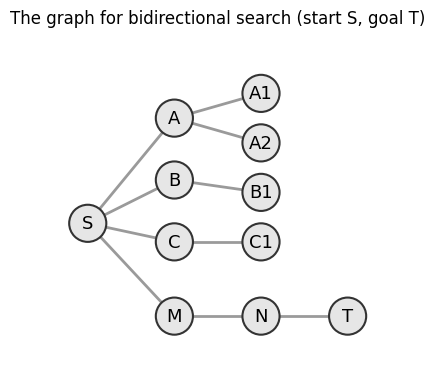

In [22]:
# Start S has many branches. The goal T sits at the end of a thin chain of nodes.
bi_graph = {
    "S":  ["A", "B", "C", "M"],
    "A":  ["S", "A1", "A2"],
    "B":  ["S", "B1"],
    "C":  ["S", "C1"],
    "M":  ["S", "N"],
    "N":  ["M", "T"],
    "T":  ["N"],
    "A1": ["A"],
    "A2": ["A"],
    "B1": ["B"],
    "C1": ["C"],
}

bi_graph_pos = {
    "S": (0.0, 1.5),
    "A": (1.4, 3.2), "B": (1.4, 2.2), "C": (1.4, 1.2), "M": (1.4, 0.0),
    "A1": (2.8, 3.6), "A2": (2.8, 2.8), "B1": (2.8, 2.0), "C1": (2.8, 1.2),
    "N": (2.8, 0.0), "T": (4.2, 0.0),
}

BI_START, BI_GOAL = "S", "T"
bg_edges, _ = graph_edges(bi_graph)
show_structure(bi_graph_pos, bg_edges, "The graph for bidirectional search (start S, goal T)")

### The algorithm

This is the same algorithm. The only difference is that the queues are plain lists, so the oldest node is removed with `pop(0)` instead of `popleft()`.

In [23]:
def expand_level_list(graph, queue, my_paths, other_paths, i_am_forward):
    meetings = []
    expanded = []

    for _ in range(len(queue)):                    # exactly one level of this queue
        node = queue.pop(0)                        # oldest node (first item of the list)
        expanded.append(node)

        for neighbor in graph[node]:
            if neighbor in other_paths:            # the other search already reached this node
                if i_am_forward:
                    meetings.append(my_paths[node] + other_paths[neighbor][::-1])
                else:
                    meetings.append(other_paths[neighbor] + my_paths[node][::-1])
            elif neighbor not in my_paths:
                my_paths[neighbor] = my_paths[node] + [neighbor]
                queue.append(neighbor)

    return meetings, expanded


def bidirectional_graph(graph, start, goal, trace=None):
    if start == goal:
        return [start]

    forward_paths = {start: [start]}
    backward_paths = {goal: [goal]}
    forward_queue = [start]                        # plain lists used as queues
    backward_queue = [goal]
    forward_done, backward_done = [], []

    while len(forward_queue) > 0 and len(backward_queue) > 0:
        if len(forward_queue) <= len(backward_queue):
            side = "forward"
            meetings, expanded = expand_level_list(graph, forward_queue, forward_paths, backward_paths, True)
            forward_done += expanded
        else:
            side = "backward"
            meetings, expanded = expand_level_list(graph, backward_queue, backward_paths, forward_paths, False)
            backward_done += expanded

        found = min(meetings, key=len) if meetings else None
        record(trace, side=side, current=expanded, forward_done=forward_done, backward_done=backward_done,
               forward_queue=forward_queue, backward_queue=backward_queue, found=found)   # animation only

        if found is not None:
            return found

    return None

### Run it

In [24]:
bi_graph_trace = []
bi_graph_path = bidirectional_graph(bi_graph, BI_START, BI_GOAL, bi_graph_trace)

last = bi_graph_trace[-1]
print("Path:", bi_graph_path)
print("Nodes expanded by the forward search: ", last["forward_done"])
print("Nodes expanded by the backward search:", last["backward_done"])
print("Total expanded:", len(last["forward_done"]) + len(last["backward_done"]))
print("A plain BFS from", BI_START, "would visit", bfs_visit_count(bi_graph, BI_START, BI_GOAL), "nodes")

Path: ['S', 'M', 'N', 'T']
Nodes expanded by the forward search:  ['S']
Nodes expanded by the backward search: ['T', 'N']
Total expanded: 3
A plain BFS from S would visit 11 nodes


The bidirectional search expanded only 3 nodes. A plain BFS visited all 11 nodes, including every dead-end branch around `S`.

Here is what happened. The forward search expanded `S` once and found four branches. The backward search then expanded `T` and `N`. When it looked at the neighbors of `N` it found `M`, which the forward search had already reached, so the two searches met.

### Watch bidirectional search on the graph

In [25]:
play(bi_graph_pos, bg_edges, frames_bidirectional(bi_graph_trace, list(bi_graph_pos)), bi_graph_path, LEGEND_BIDI)

---
# Part 3: Uniform Cost Search (UCS)

### The idea

BFS counts steps, so it assumes every step costs the same. In real problems it often does not. A short road can be a slow toll road, and a longer route can be faster overall.

UCS looks at the **total cost** from the start. It keeps all the nodes that are waiting in a **priority queue**, and it always takes out the one with the **smallest total cost so far**.

The key fact: the first time the goal comes out of the priority queue, no cheaper path can exist, because everything cheaper has already been taken out.

What the code does:

1. Put the start in the priority queue with cost 0.
2. Take out the cheapest item. If its node was already visited, skip it.
3. Mark it visited and remember its cost. If it is the goal, return the path and the cost.
4. For each neighbor, add `(cost so far + cost of that road, path to the neighbor)` to the priority queue.

Each item is a tuple `(total cost, path)`. Since tuples are compared by their first value, the cheapest total cost always comes out first.

In the animation, a number under a node in round brackets, like `(7)`, is the best cost found so far for a node that is still waiting. A number without brackets is the final cost of a node that has been visited. A waiting node's cost can go down if a cheaper road to it turns up.

## Example 1: UCS on a weighted tree (using the built-in priority queue `heapq`)

### Build the tree

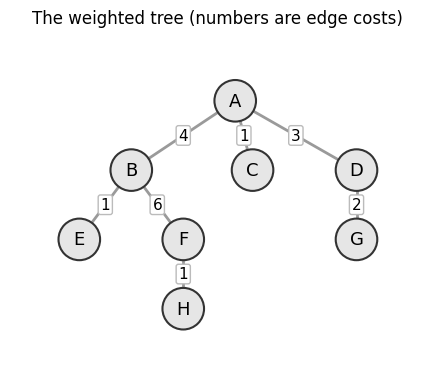

In [26]:
# Each child is stored together with the cost of the road that leads to it: (child, cost)
wtree = {
    "A": [("B", 4), ("C", 1), ("D", 3)],
    "B": [("E", 1), ("F", 6)],
    "C": [],
    "D": [("G", 2)],
    "E": [],
    "F": [("H", 1)],
    "G": [],
    "H": [],
}

wtree_pos = {
    "A": (2.25, 3),
    "B": (0.75, 2), "C": (2.5, 2), "D": (4.0, 2),
    "E": (0.0, 1),  "F": (1.5, 1), "G": (4.0, 1),
    "H": (1.5, 0),
}

W_ROOT, W_TREE_GOAL = "A", "H"
wt_edges, wt_weights = tree_edges(wtree)
show_structure(wtree_pos, wt_edges, "The weighted tree (numbers are edge costs)", wt_weights)

### The algorithm

The frontier is a normal list that `heapq` keeps organised. `heappush` adds an item and `heappop` always returns the smallest one. A tree has no cycles, so there is no need to check for repeats, but we still store each visited node's cost in the `visited` dictionary so the animation can show it.

In [101]:
import heapq

def ucs_tree(tree, root, goal, trace=None):
    frontier = []                                      # the priority queue
    heapq.heappush(frontier, (0, [root]))              # (total cost, path)
    visited = {}                                       # node -> cost when it was visited

    while len(frontier) > 0:
        cost, path = heapq.heappop(frontier)           # the cheapest item
        node = path[-1]
        visited[node] = cost

        if node == goal:
            record(trace, current=node, cost=cost, frontier=[(c, p[-1]) for c, p in frontier], visited=visited)  # animation only
            return path, cost

        for child, weight in tree[node]:
            heapq.heappush(frontier, (cost + weight, path + [child]))

        record(trace, current=node, cost=cost, frontier=[(c, p[-1]) for c, p in frontier], visited=visited)      # animation only

    return None, None

### Run it

In [100]:
ucs_tree_trace = []
ucs_tree_path, ucs_tree_cost = ucs_tree(wtree, W_ROOT, W_TREE_GOAL, ucs_tree_trace)

print("Path:", ucs_tree_path)
print("Total cost:", ucs_tree_cost)
print("Order of visits:", [(s["current"], s["cost"]) for s in ucs_tree_trace])

Adding B to the frontier with total cost 4
Adding C to the frontier with total cost 1
Adding D to the frontier with total cost 3
Adding G to the frontier with total cost 5
Adding E to the frontier with total cost 5
Adding F to the frontier with total cost 10
Adding H to the frontier with total cost 11
Path: ['A', 'B', 'F', 'H']
Total cost: 11
Order of visits: [('A', 0), ('C', 1), ('D', 3), ('B', 4), ('E', 5), ('G', 5), ('F', 10), ('H', 11)]


The nodes are visited in order of total cost, not in order of depth. `C` costs 1 so it comes out before `B`, even though they are on the same level. `F` costs 10 and sits one level above `H`, which costs 11, so `F` comes first.

### Watch UCS on the tree

In [29]:
play(wtree_pos, wt_edges, frames_ucs(ucs_tree_trace, list(wtree_pos)), ucs_tree_path, LEGEND_UCS, wt_weights)

---
## Example 2: UCS on a weighted graph (using a plain list as the priority queue)

Here we do not use `heapq`. The frontier is a plain list, and each time we need the cheapest item we find it with `min()` and take it out with `remove()`. This is slower for big problems, but it is easy to read and does exactly the same job.

This graph has been built so that the path with the **fewest edges is not the cheapest path**. BFS would pick the first one and UCS picks the second.

### Build the graph

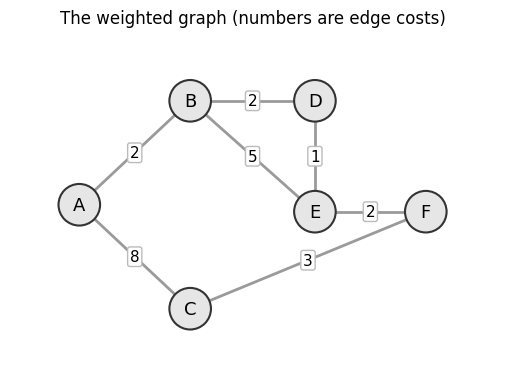

In [30]:
# Edges go both ways, so each road is listed under both of its ends.
wgraph = {
    "A": [("B", 2), ("C", 8)],
    "B": [("A", 2), ("D", 2), ("E", 5)],
    "C": [("A", 8), ("F", 3)],
    "D": [("B", 2), ("E", 1)],
    "E": [("B", 5), ("D", 1), ("F", 2)],
    "F": [("E", 2), ("C", 3)],
}

wgraph_pos = {
    "A": (0.0, 1.5),
    "B": (1.6, 3.0), "D": (3.4, 3.0),
    "E": (3.4, 1.4), "F": (5.0, 1.4),
    "C": (1.6, 0.0),
}

W_START, W_GOAL = "A", "F"
wg_edges, wg_weights = graph_edges(wgraph)
show_structure(wgraph_pos, wg_edges, "The weighted graph (numbers are edge costs)", wg_weights)

### The algorithm

Since a graph can have cycles, we skip a node if it was already visited. A node can sit in the list more than once, for example when a cheaper road to it is found later. The cheaper copy always comes out first, and the expensive copy is skipped when its turn comes.

In [105]:
def ucs_graph(graph, start, goal, trace=None):
    frontier = [(0, [start])]                          # a list of (total cost, path)
    visited = {}                                       # node -> cost when it was visited

    while len(frontier) > 0:
        cheapest = min(frontier)                       # smallest total cost
        frontier.remove(cheapest)
        cost, path = cheapest
        node = path[-1]

        if node in visited:                            # a cheaper copy was already visited
            continue
        visited[node] = cost

        if node == goal:
            record(trace, current=node, cost=cost, frontier=[(c, p[-1]) for c, p in frontier], visited=visited)  # animation only
            return path, cost

        for neighbor, weight in graph[node]:
            if neighbor not in visited:                           
                frontier.append((cost + weight, path + [neighbor]))

        record(trace, current=node, cost=cost, frontier=[(c, p[-1]) for c, p in frontier], visited=visited)      # animation only

    return None, None

### Run it

In [103]:
ucs_graph_trace = []
ucs_graph_path, ucs_graph_cost = ucs_graph(wgraph, W_START, W_GOAL, ucs_graph_trace)

print("UCS path:", ucs_graph_path, "with total cost", ucs_graph_cost)
print("Order of visits:", [(s["current"], s["cost"]) for s in ucs_graph_trace])

# for comparison: the route with the fewest edges
print()
print("The path with the fewest edges is A -> C -> F. Its cost is", 8 + 3)

UCS path: ['A', 'B', 'D', 'E', 'F'] with total cost 7
Order of visits: [('A', 0), ('B', 2), ('D', 4), ('E', 5), ('F', 7)]

The path with the fewest edges is A -> C -> F. Its cost is 11


`A -> C -> F` has only two edges, but it costs 11. UCS found `A -> B -> D -> E -> F` instead. That route has four edges and costs only 7.

In the animation, watch what happens to `E`. It is first discovered through `B` with a cost of 7. A little later the search reaches `D` and finds a cheaper way to `E`, with a cost of 5. The note under `E` changes from `(7)` to `(5)`. The older, more expensive entry stays in the priority queue and is drawn in grey, because `E` has already been visited through the cheaper route. If that entry ever came out it would simply be skipped.

### Watch UCS on the graph

In [104]:
play(wgraph_pos, wg_edges, frames_ucs(ucs_graph_trace, list(wgraph_pos)), ucs_graph_path, LEGEND_UCS, wg_weights)

---
# Summary

| | IDS | Bidirectional search | UCS |
|---|---|---|---|
| Based on | DFS repeated with a growing depth limit | Two BFS runs, one from each end | A priority queue ordered by total cost |
| Data structure | Stack | Two queues and two dictionaries of paths | Priority queue |
| Finds the shortest path (fewest steps)? | Yes | Yes | Not its goal, it minimises cost |
| Finds the cheapest path when costs differ? | No | No | Yes |
| Memory | Small, like DFS | Larger, two searches at once | Can be large |
| Needs | Nothing special | Edges that can be followed backwards | Costs that are not negative |
| Best used when | The answer is deep and memory is limited | You know both the start and the goal | Roads have different costs |

One way to remember them:

* BFS and IDS count steps.
* UCS adds up costs.
* Bidirectional search is a way of making BFS cheaper by searching from both ends.

Notice that if every edge costs 1, UCS behaves exactly like BFS.